# Unidad 32. Series y comparaciones temporales con Matplotlib

**Bloque:** Matplotlib (UT3) · **Tiempo orientativo:** 5–7 horas

En la unidad anterior creaste una línea clara. Ahora trabajarás con series temporales: datos cuya posición en el eje horizontal representa una fecha, una hora o una iteración ordenada. Aprenderás a comparar series sin ocultar la escala ni sugerir conclusiones que los datos no sostienen.

**Prerequisitos:** unidad 31, arrays de NumPy y selección elemental de columnas en Pandas.

## Resultados de aprendizaje

Al terminar podrás:

- preparar una serie temporal ordenada para representarla;
- dibujar varias series comparables en un mismo eje;
- decidir cuándo dos escalas o unidades no deben mezclarse;
- configurar leyendas, marcas temporales y cuadrícula para facilitar la lectura;
- describir tendencias, máximos y diferencias sin afirmar causalidad.

**Pregunta guía:** ¿cómo evolucionan una o varias medidas comparables a lo largo de un intervalo conocido?

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 1. Una serie temporal necesita orden y contexto

Una línea une puntos en el orden en que se los entregas. Por ello, una columna de fechas debe convertirse a fecha y ordenarse antes de dibujarla. Si un fichero llega desordenado, el gráfico puede zigzaguear aunque los datos sean correctos.

La siguiente tabla contiene lecturas de consumo de dos días. `pd.to_datetime` convierte el texto en fechas y `sort_values` asegura el orden. Observa que el eje vertical incluye unidad y que el título describe el periodo.

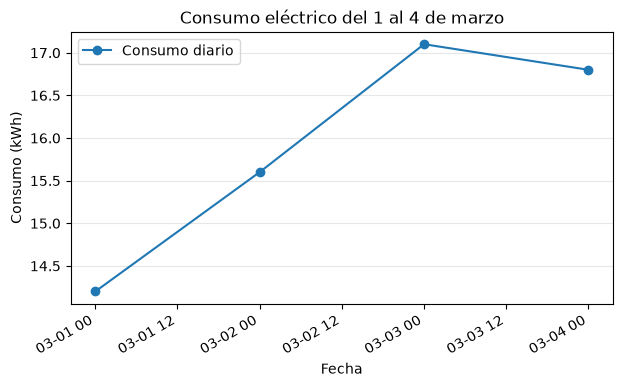

       fecha  consumo_kwh
1 2026-03-01         14.2
3 2026-03-02         15.6
2 2026-03-03         17.1
0 2026-03-04         16.8


In [3]:
consumo = pd.DataFrame(
    {
        "fecha": ["2026-03-04", "2026-03-01", "2026-03-03", "2026-03-02"],
        "consumo_kwh": [16.8, 14.2, 17.1, 15.6],
    }
)
consumo["fecha"] = pd.to_datetime(consumo["fecha"])
consumo = consumo.sort_values("fecha")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(consumo["fecha"], consumo["consumo_kwh"], marker="o", label="Consumo diario")
ax.set(title="Consumo eléctrico del 1 al 4 de marzo", xlabel="Fecha", ylabel="Consumo (kWh)")
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.autofmt_xdate()
plt.show()

print(consumo)

## 2. Comparar dos series con la misma unidad

Dos líneas en el mismo eje funcionan bien cuando comparten:

- la misma variable horizontal (por ejemplo, la fecha);
- la misma magnitud y unidad en vertical;
- un rango de observación comparable.

La leyenda debe nombrar las series. Añadir marcadores y estilos de línea distintos evita que la distinción dependa solo del color. `ax.set_ylim` puede ser útil para fijar un rango conocido, pero recortar el eje para exagerar pequeñas diferencias es una decisión engañosa si no se explica.

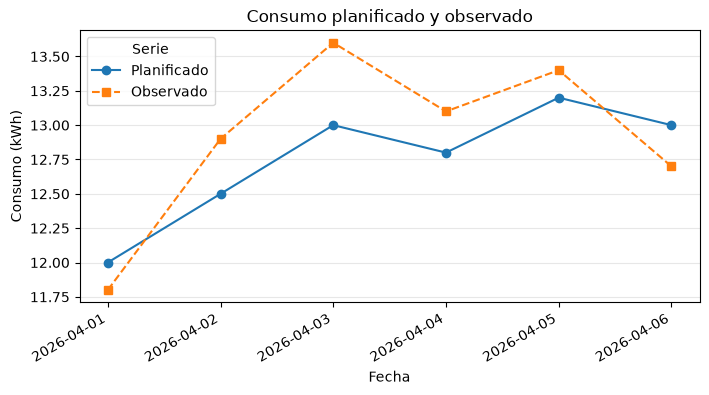

Mayor diferencia observada: 0.5999999999999996 kWh


In [4]:
fechas = pd.date_range("2026-04-01", periods=6, freq="D")
consumo_planificado = np.array([12.0, 12.5, 13.0, 12.8, 13.2, 13.0])
consumo_observado = np.array([11.8, 12.9, 13.6, 13.1, 13.4, 12.7])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(fechas, consumo_planificado, marker="o", label="Planificado")
ax.plot(fechas, consumo_observado, marker="s", linestyle="--", label="Observado")
ax.set(title="Consumo planificado y observado", xlabel="Fecha", ylabel="Consumo (kWh)")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Serie")
fig.autofmt_xdate()
plt.show()

diferencia = consumo_observado - consumo_planificado
print("Mayor diferencia observada:", diferencia.max(), "kWh")

## 3. Escalas y unidades: lo que no debes mezclar

No representes directamente en el mismo eje, por ejemplo, consumo en kWh y temperatura en °C: sus unidades son distintas. Más adelante estudiaremos figuras con varios ejes para comparar perspectivas; por ahora, utiliza dos gráficos coordinados. Así evitas que una escala grande haga invisible a la otra.

También conviene revisar el origen del eje vertical. Empezar en cero es habitual cuando se comparan cantidades; para ver variaciones pequeñas puede utilizarse otro límite, pero el título, el rango y el objetivo deben hacer explícita esa elección.

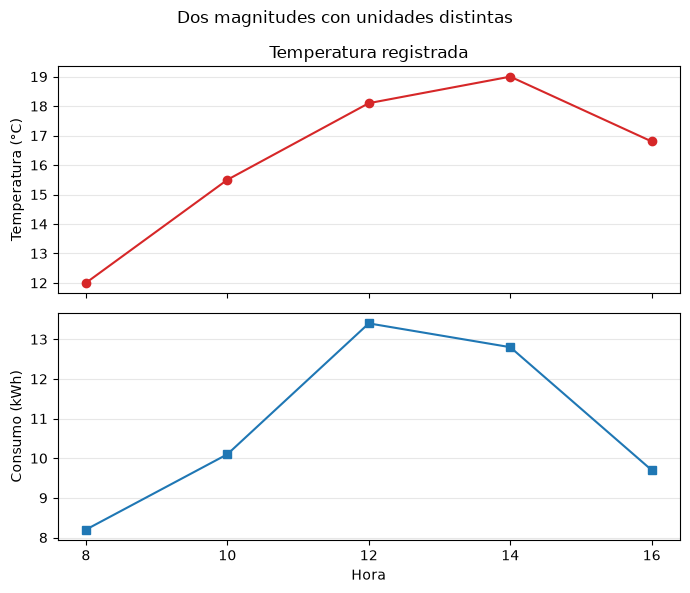

In [5]:
horas = np.array([8, 10, 12, 14, 16])
temperatura_c = np.array([12.0, 15.5, 18.1, 19.0, 16.8])
consumo_kwh = np.array([8.2, 10.1, 13.4, 12.8, 9.7])

fig, ejes = plt.subplots(nrows=2, ncols=1, figsize=(7, 6), sharex=True)
ejes[0].plot(horas, temperatura_c, marker="o", color="tab:red")
ejes[0].set(title="Temperatura registrada", ylabel="Temperatura (°C)")
ejes[0].grid(axis="y", alpha=0.3)

ejes[1].plot(horas, consumo_kwh, marker="s", color="tab:blue")
ejes[1].set(xlabel="Hora", ylabel="Consumo (kWh)")
ejes[1].set_xticks(horas)
ejes[1].grid(axis="y", alpha=0.3)

fig.suptitle("Dos magnitudes con unidades distintas")
fig.tight_layout()
plt.show()

## 4. Interpretar con prudencia

En el segundo ejemplo, el consumo observado supera al planificado algunos días y queda por debajo otros. Ese patrón puede orientar una revisión, pero no permite asignar una causa a cada diferencia. Las fechas no incluyen información sobre ocupación, equipos, temperatura ni incidencias.

Una buena conclusión responde a tres partes: qué se observa, en qué intervalo y qué información falta para explicar el patrón. Esta forma de comunicar será obligatoria en los ejercicios y en el proyecto final.

## Práctica guiada

Completa la lectura del siguiente `DataFrame`:

1. Comprueba que las fechas están ordenadas.
2. Localiza el día de mayor diferencia absoluta entre lo observado y lo esperado.
3. Cambia el título para que formule una pregunta concreta.
4. Escribe una frase que describa el resultado sin atribuirle una causa.

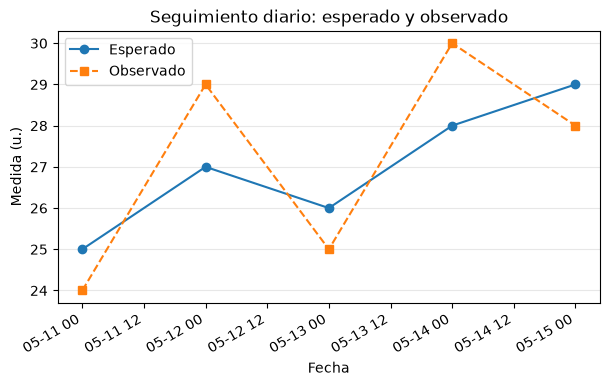

       fecha  esperado  observado  diferencia
0 2026-05-11        25         24          -1
1 2026-05-12        27         29           2
2 2026-05-13        26         25          -1
3 2026-05-14        28         30           2
4 2026-05-15        29         28          -1


In [6]:
seguimiento = pd.DataFrame(
    {
        "fecha": pd.date_range("2026-05-11", periods=5, freq="D"),
        "esperado": [25, 27, 26, 28, 29],
        "observado": [24, 29, 25, 30, 28],
    }
)
seguimiento["diferencia"] = seguimiento["observado"] - seguimiento["esperado"]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(seguimiento["fecha"], seguimiento["esperado"], marker="o", label="Esperado")
ax.plot(seguimiento["fecha"], seguimiento["observado"], marker="s", linestyle="--", label="Observado")
ax.set(title="Seguimiento diario: esperado y observado", xlabel="Fecha", ylabel="Medida (u.)")
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.autofmt_xdate()
plt.show()

print(seguimiento)

## Ejercicios

### Ejercicio 32.01 · Orden antes de dibujar

Crea un `DataFrame` con estas filas, convierte `fecha` con `pd.to_datetime`, ordénalo y representa la serie de visitantes:

```python
datos = {"fecha": ["2026-01-03", "2026-01-01", "2026-01-02"], "visitantes": [86, 74, 91]}
```

La figura debe incluir título, fechas en x, visitantes en y y cuadrícula horizontal. Comprueba con `is_monotonic_increasing` que las fechas quedaron ordenadas.

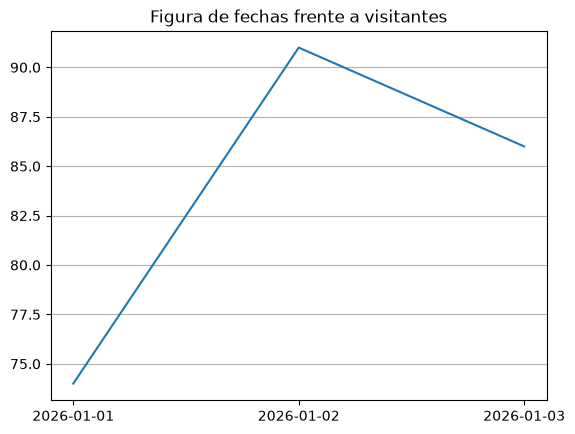

In [7]:
# Escribe aquí tu solución del ejercicio 32.01.
datos = {"fecha": ["2026-01-03", "2026-01-01", "2026-01-02"], "visitantes": [86, 74, 91]}

df = pd.DataFrame(datos)
df["fecha"] = pd.to_datetime(df["fecha"])
df = df.sort_values("fecha")

assert df["fecha"].is_monotonic_increasing

fix, ax = plt.subplots()
ax.plot(df["fecha"], df["visitantes"])
ax.set_title("Figura de fechas frente a visitantes")
ax.grid(axis="y")

# Adicional
ax.set_xticks(df["fecha"])
fig.autofmt_xdate()

plt.show()


### Ejercicio 32.02 · Dos series, una unidad

Representa en una misma figura las ventas previstas y realizadas en miles de euros durante seis meses. Usa `meses = np.arange(1, 7)`, `previstas = [18, 20, 21, 23, 22, 25]` y `realizadas = [17, 21, 20, 24, 23, 26]`. Diferencia las líneas mediante marcador y estilo, añade leyenda y escribe una conclusión limitada a los meses observados.

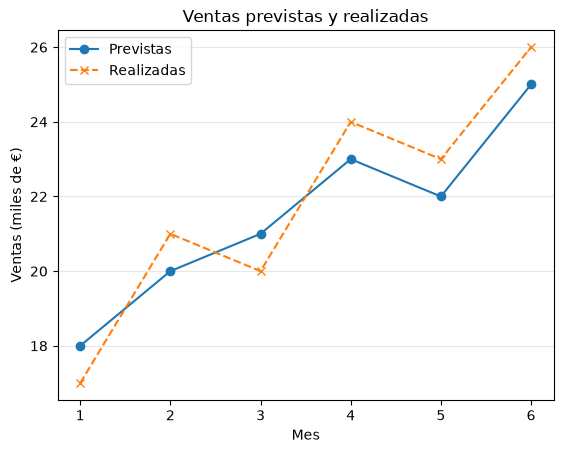

In [8]:
# Escribe aquí tu solución del ejercicio 32.02.
meses = np.arange(1, 7)
previstas = [18, 20, 21, 23, 22, 25]
realizadas = [17, 21, 20, 24, 23, 26]

fig, ax = plt.subplots()

ax.plot(meses, previstas, linestyle="-", marker="o", label="Previstas")
ax.plot(meses, realizadas, linestyle="--", marker="x", label="Realizadas")
ax.set(title="Ventas previstas y realizadas", xlabel="Mes", ylabel="Ventas (miles de €)")
ax.set_xticks(meses)
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.show()

# Conclusión: Entre los meses 1 y 6 ambas series siguen una tendencia creciente. Las ventas
# realizadas quedan 1 mil € por debajo en los meses 1 y 3, pero superan en 1 mil € a las
# previstas en los meses 2, 4, 5 y 6, sin que estos datos permitan afirmar la causa.


### Ejercicio 32.03 · Escalas compatibles

Tienes `temperatura_c = [11, 13, 16, 18]` y `produccion_unidades = [140, 155, 151, 166]` para cuatro días. Crea **dos ejes apilados con x compartida**, uno por magnitud. Explica en un comentario por qué no usas un único eje vertical.

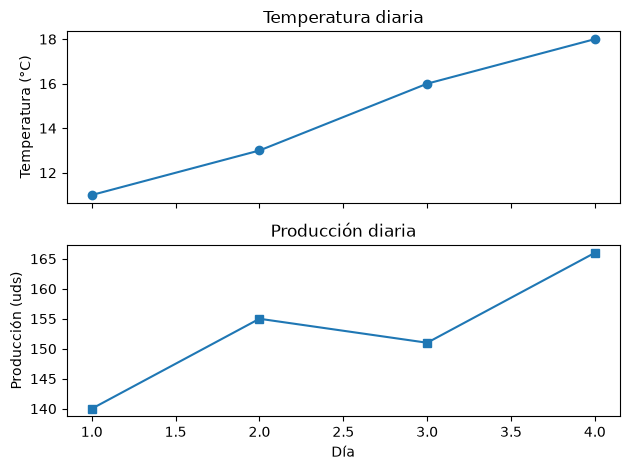

In [9]:
# Escribe aquí tu solución del ejercicio 32.03.

# No se usa un único eje vertical porque la temperatura (°C) y la producción (unidades)
# tienen magnitudes y escalas distintas; mezclarlas ocultaría los cambios de la serie menor.
dias = np.arange(1, 5)
temperatura_c = [11, 13, 16, 18]
produccion_unidades = [140, 155, 151, 166]

fig, ejes = plt.subplots(nrows=2, ncols=1, sharex=True)

ejes[0].plot(dias, temperatura_c, marker="o")
ejes[0].set(title="Temperatura diaria", ylabel="Temperatura (°C)")

ejes[1].plot(dias, produccion_unidades, marker="s")
ejes[1].set(title="Producción diaria", xlabel="Día", ylabel="Producción (uds)")

fig.tight_layout()
plt.show()


### Ejercicio 32.04 · Función de comparación

Define `comparar_series(x, primera, segunda, etiqueta_primera, etiqueta_segunda, etiqueta_y)` que devuelva `fig, ax`. La función debe validar que los tres arrays tienen la misma longitud, dibujar las dos líneas, configurar etiquetas y devolver los objetos. Pruébala con cinco observaciones.

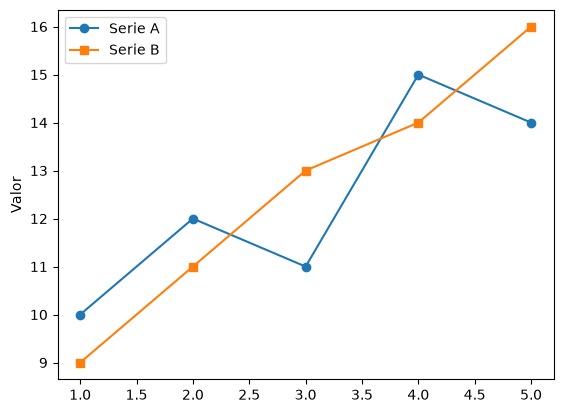

In [13]:
# Escribe aquí tu solución del ejercicio 32.04.
def comparar_series(x, primera, segunda, etiqueta_primera, etiqueta_segunda, etiqueta_y):
    if not len(x) == len(primera) == len(segunda):
        raise ValueError("No tienen la misma longitud")

    fig, ax = plt.subplots()
    ax.plot(x, primera, marker = "o", label=etiqueta_primera)
    ax.plot(x, segunda, marker = "s", label=etiqueta_segunda)
    ax.set_ylabel(etiqueta_y)
    ax.legend()
    return fig, ax

x_prueba = np.arange(1, 6)
serie_a = [10, 12, 11, 15, 14]
serie_b = [9, 11, 13, 14, 16]

fig, ax = comparar_series(
    x_prueba,
    serie_a,
    serie_b,
    etiqueta_primera="Serie A",
    etiqueta_segunda="Serie B",
    etiqueta_y="Valor",
)
plt.show()
    

### Ejercicio 32.05 · Miniproyecto: seguimiento semanal

Construye un `DataFrame` de siete días con valores objetivo y reales de consumo de agua (litros). Crea una figura comparativa, calcula la diferencia diaria y muestra qué día tiene la mayor diferencia absoluta. La entrega incluye el gráfico y un texto de 60–90 palabras que indique el patrón, el intervalo analizado y dos datos adicionales necesarios para investigar su causa.


Día con mayor diferencia absoluta: 2026-11-19 | Diferencia absoluta: 17 L (Real: 157 L vs Objetivo: 140 L)


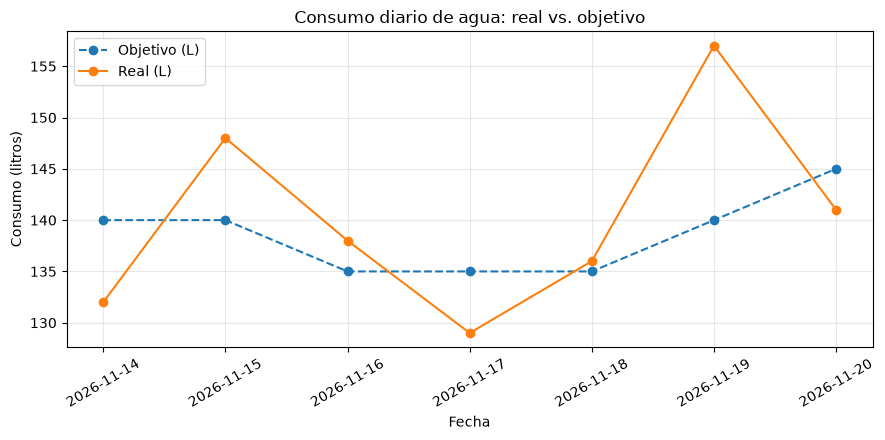


Palabras en el texto: 80
Durante el intervalo del 14 al 20 de noviembre de 2026, el consumo real de agua oscila alrededor del objetivo diario, alternando jornadas por debajo y por encima de la meta, con la mayor diferencia absoluta el 19 de noviembre (17 litros). Para investigar qué está detrás de estas variaciones sin asumir causas directas, harían falta dos datos adicionales: el número de personas presentes en el domicilio cada día y el registro de tareas o usos puntuales de mayor caudal.


In [ ]:
# Escribe aquí tu solución del ejercicio 32.05.
df = pd.DataFrame({
    "fecha": [
        "2026-11-14",
        "2026-11-15",
        "2026-11-16",
        "2026-11-17",
        "2026-11-18",
        "2026-11-19",
        "2026-11-20",
    ],
    "objetivo_l": [140, 140, 135, 135, 135, 140, 145],
    "real_l": [132, 148, 138, 129, 136, 157, 141],
})

df["fecha"] = pd.to_datetime(df["fecha"])

# Diferencia normal (con signo): real - objetivo. Sirve para ver la dirección del desvío (exceso o ahorro) y el balance neto.
    # Si es positiva (+17), hubo 17 L de más respecto al objetivo.
    # Si es negativa (-8), hubo 8 L de menos respecto al objetivo.
# Diferencia absoluta: |real - objetivo| (con .abs()). Quita el signo y deja solo el tamaño del desvío:
    #Un día con -8 L pasa a tener una diferencia absoluta de 8 L.
    #Un día con +17 L tiene una diferencia absoluta de 17 L.

df["diferencia_l"] = df["real_l"] - df["objetivo_l"] # Calcular la diferencia diaria.
df["diferencia_abs_l"] = df["diferencia_l"].abs() # Calcular la diferencia absoluta.

# Día con mayor diferencia absoluta
idx_max = df["diferencia_abs_l"].idxmax()
fila_max = df.loc[idx_max]

print(
    f"\nDía con mayor diferencia absoluta: {fila_max['fecha'].strftime('%Y-%m-%d')} "
    f"| Diferencia absoluta: {fila_max['diferencia_abs_l']} L "
    f"(Real: {fila_max['real_l']} L vs Objetivo: {fila_max['objetivo_l']} L)"
)

fig, ax = plt.subplots(figsize=(9, 4.5)) # 9 pulgadas por 4.5 ancho (2:1)

ax.plot(df["fecha"], df["objetivo_l"], marker="o", linestyle="--", label="Objetivo (L)")
ax.plot(df["fecha"], df["real_l"], marker="o", label="Real (L)")

ax.set_title("Consumo diario de agua: real vs. objetivo")
ax.set_xlabel("Fecha")
ax.set_ylabel("Consumo (litros)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.xticks(rotation=30) #Sirve para inclinar 30 grados las etiquetas del eje X (las fechas) y evitar que se pisen o choquen entre sí.
plt.tight_layout() # Ajusta automáticamente los márgenes y espacios alrededor del gráfico
plt.show()

texto_analisis = (
    "Durante el intervalo del 14 al 20 de noviembre de 2026, el consumo real de agua "
    "oscila alrededor del objetivo diario, alternando jornadas por debajo y por encima de la meta, "
    "con la mayor diferencia absoluta el 19 de noviembre (17 litros). Para investigar qué está "
    "detrás de estas variaciones sin asumir causas directas, harían falta dos datos adicionales: "
    "el número de personas presentes en el domicilio cada día y el registro de tareas o usos "
    "puntuales de mayor caudal."
)

print(texto_analisis)

 


## Autoevaluación

1. ¿Qué puede ocurrir si dibujas una serie de fechas sin ordenarla?
2. ¿Qué tres condiciones hacen razonable comparar dos líneas en un mismo eje?
3. ¿Por qué no conviene mezclar directamente kWh y °C en el mismo eje vertical?
4. ¿Qué parte de una conclusión debe separar observación y explicación?
5. ¿Qué método de Pandas permite comprobar que una serie ya está ordenada de forma creciente?

**Qué debes saber hacer:** ordenar y visualizar series temporales, comparar magnitudes compatibles y describir el resultado sin convertir una coincidencia temporal en una explicación causal.